In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.xception import Xception,preprocess_input,decode_predictions
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
from tensorflow.keras.preprocessing import image

In [ ]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

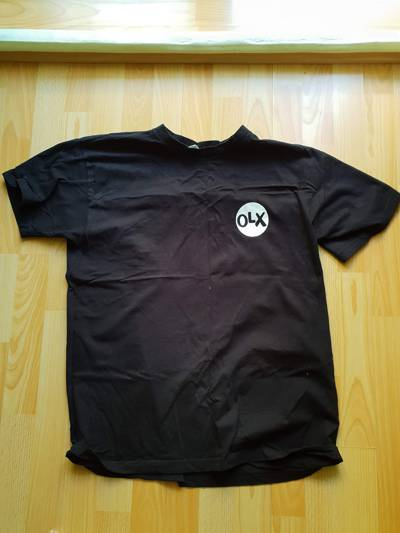

In [3]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

In [3]:
img = load_img(fullname, target_size=(299, 299))

NameError: name 'fullname' is not defined

In [ ]:
x = np.array(img)
x.shape

(299, 299, 3)

In [ ]:
model = Xception(weights='imagenet',input_shape=(299,299,3))

In [ ]:
X = np.array([x])

In [ ]:
X.shape

(1, 299, 299, 3)

In [ ]:
X = preprocess_input(X)

In [ ]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


(1, 1000)

In [ ]:
decode_predictions(pred)

[[('n03595614', 'jersey', np.float32(0.6819633)),
  ('n02916936', 'bulletproof_vest', np.float32(0.038140032)),
  ('n04370456', 'sweatshirt', np.float32(0.034324802)),
  ('n03710637', 'maillot', np.float32(0.011354214)),
  ('n04525038', 'velvet', np.float32(0.0018453582))]]

## **CNN**

In [8]:
train_gen = ImageDataGenerator(preprocessing_function = preprocess_input)
train_ds = train_gen.flow_from_directory('./clothing-dataset-small/train',
target_size = (150,150),
batch_size = 32)

Found 3068 images belonging to 10 classes.


In [9]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

In [10]:
X,y = next(train_ds)

In [11]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory('./clothing-dataset-small/validation',
                                    target_size = (150,150),
                                    batch_size = 32,
                                    shuffle = False)

Found 341 images belonging to 10 classes.


**Building the model**

In [12]:
base_model = Xception(weights='imagenet',
                      include_top=False,
                      input_shape=(150,150,3))
base_model.trainable = False

inputs = keras.Input(shape=(150,150,3))
base = base_model(inputs,training = False)
vectors = keras.layers.GlobalAveragePooling2D()(base)
outputs = keras.layers.Dense(10)(vectors)
model = keras.Model(inputs,outputs)

In [5]:
base_model.summary()

Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 74, 74,    │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 74, 74,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 74, 74,    │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 72, 72,    │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 72, 72,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 72, 72,    │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 72, 72,    │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 72, 72,    │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 72, 72,    │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 72, 72,    │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 72, 72,    │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 36, 36,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 36, 36,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 36, 36,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 36, 36,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 36, 36,    │          0 │ add[0][0]       

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 20,861,480 (79.58 MB)

**Optimizer and loss**

In [13]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

loss = keras.losses.CategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer,loss=loss,metrics=['accuracy'])

**Training the model**

In [14]:
history = model.fit(train_ds,epochs=5,validation_data=val_ds)

Epoch 1/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 260s 3s/step - accuracy: 0.6636 - loss: 1.2427 - val_accuracy: 0.7683 - val_loss: 0.8051
Epoch 2/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 246s 3s/step - accuracy: 0.8077 - loss: 0.6371 - val_accuracy: 0.7918 - val_loss: 0.8493
Epoch 3/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 273s 3s/step - accuracy: 0.8729 - loss: 0.3952 - val_accuracy: 0.7771 - val_loss: 0.9350
Epoch 4/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.9123 - loss: 0.2658 - val_accuracy: 0.7918 - val_loss: 0.8818
Epoch 5/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.9384 - loss: 0.1716 - val_accuracy: 0.8035 - val_loss: 0.9040


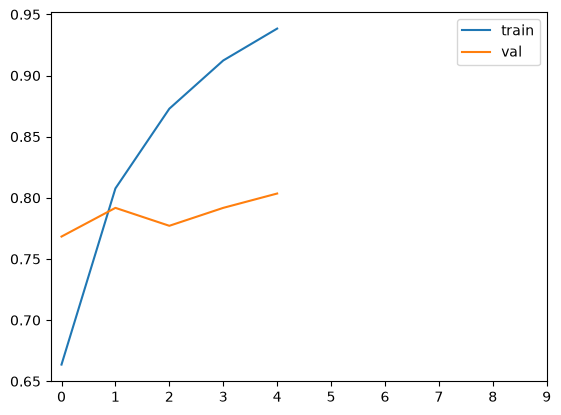

In [17]:
plt.plot(history.history['accuracy'],label = 'train')
plt.plot(history.history['val_accuracy'],label = 'val')
plt.xticks(np.arange(10))
plt.legend()

**Adjusting the learning rate**

In [15]:
def make_model(learning_rate=0.01):
    base_model = Xception(weights='imagenet',
                          include_top = False,
                          input_shape = (150,150,3))
    base_model.trainable = False

    inputs = keras.Input(shape=(150,150,3))
    base = base_model(inputs,training = False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs,outputs)

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer,loss=loss,metrics=['accuracy'])

    return model

In [18]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds,epochs=5,validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
Epoch 1/5
15/96 ━━━━━━━━━━━━━━━━━━━━ 2:52 2s/step - accuracy: 0.1937 - loss: 2.3500

KeyboardInterrupt: 

**Selecting the best learning rate**

In [28]:
model.save_weights('model_v1.weights.h5')

In [29]:
checkpoint  = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode = 'max')

In [30]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(train_ds,epochs=5,
                    validation_data=val_ds,
                    callbacks=[checkpoint])

Epoch 1/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6320 - loss: 1.0857

96/96 ━━━━━━━━━━━━━━━━━━━━ 271s 3s/step - accuracy: 0.6320 - loss: 1.0857 - val_accuracy: 0.7947 - val_loss: 0.7269
Epoch 2/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7872 - loss: 0.6312

96/96 ━━━━━━━━━━━━━━━━━━━━ 293s 3s/step - accuracy: 0.7872 - loss: 0.6312 - val_accuracy: 0.8006 - val_loss: 0.6322
Epoch 3/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8347 - loss: 0.5110

96/96 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.8347 - loss: 0.5110 - val_accuracy: 0.8094 - val_loss: 0.6020
Epoch 4/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8621 - loss: 0.4324

96/96 ━━━━━━━━━━━━━━━━━━━━ 275s 3s/step - accuracy: 0.8621 - loss: 0.4324 - val_accuracy: 0.8182 - val_loss: 0.5723
Epoch 5/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 280s 3s/step - accuracy: 0.8885 - loss: 0.3698 - val_accuracy: 0.8182 - val_loss: 0.5698


**Adding more layers**

In [21]:
def make_model(learning_rate=0.01,size_inner = 10):
    base_model = Xception(weights='imagenet',
                          include_top = False,
                          input_shape = (150,150,3))
    base_model.trainable = False

    inputs = keras.Input(shape=(150,150,3))
    base = base_model(inputs,training = False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    inner = keras.layers.Dense(size_inner,activation='relu')(vectors)
    outputs = keras.layers.Dense(10)(inner)
    model = keras.Model(inputs,outputs)

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits = True)

    model.compile(optimizer = optimizer,
                  loss = loss,
                  metrics = ['accuracy'])

    return model

In [22]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=2, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 302s 3s/step - accuracy: 0.5293 - loss: 1.4476 - val_accuracy: 0.6833 - val_loss: 1.0188
Epoch 2/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.7138 - loss: 0.8503 - val_accuracy: 0.7801 - val_loss: 0.7643


100
Epoch 1/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 299s 3s/step - accuracy: 0.6666 - loss: 0.9763 - val_accuracy: 0.7713 - val_loss: 0.6849
Epoch 2/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.8253 - loss: 0.5178 - val_accuracy: 0.7977 - val_loss: 0.5938


1000
Epoch 1/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 233s 2s/step - accuracy: 0.6835 - loss: 0.9544 - val_accuracy: 0.7273 - val_loss: 0.8095
Epoch 2/2
96/96 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.8341 - loss: 0.4592 - val_accuracy: 0.8270 - val_loss: 0.5643




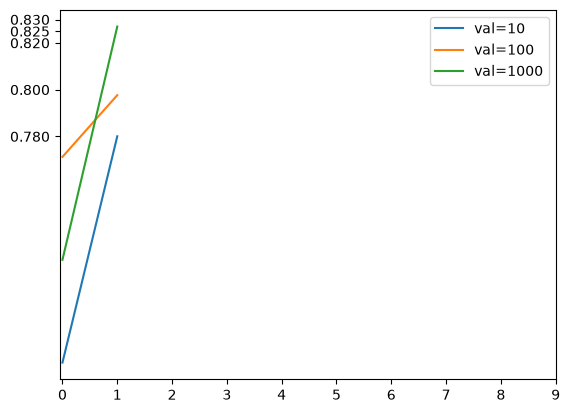

In [24]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend();

**Regularization and dropout**

In [25]:
def make_model(learning_rate=0.01,size_inner=10,drop_rate = 0.5):
    base_model = Xception(weights='imagenet',
                          include_top = False,
                          input_shape = (150,150,3))
    base_model.trainable = False

    inputs = keras.Input(shape=(150,150,3))
    base = base_model(inputs,training = False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    inner = keras.layers.Dense(size_inner,activation='relu')(vectors)
    drop = keras.layers.Dropout(drop_rate)(inner)

    outputs = keras.layers.Dense(10)(drop)
    model = keras.Model(inputs,outputs)

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(optimizer=optimizer,loss =loss,metrics=['accuracy'])

    return model

In [30]:
path = 'clothing-dataset-small/test/pants/c8d21106-bbdb-4e8d-83e4-bf3d14e54c16.jpg'

In [31]:
img = load_img(path, target_size=(299, 299))

In [32]:
x = np.array(img)
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [33]:
X = preprocess_input(X)
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [27]:
classes = [
    'dress',
    'hat',
    'longsleeve',
    'outwear',
    'pants',
    'shirt',
    'shoes',
    'shorts',
    'skirt',
    't-shirt'
]

In [34]:
dict(zip(classes, pred[0]))

{'dress': np.float32(-0.51063716),
 'hat': np.float32(-1.5848522),
 'longsleeve': np.float32(-0.8223982),
 'outwear': np.float32(-1.0681156),
 'pants': np.float32(3.6980562),
 'shirt': np.float32(-0.90943277),
 'shoes': np.float32(-1.4582615),
 'shorts': np.float32(2.9388947),
 'skirt': np.float32(-1.0894486),
 't-shirt': np.float32(-1.0077168)}